# Testing inference: how many neurons must the trigger recruit?

Companion to notebook 15: instead of truncating the trigger *in time*, this notebook
lesions it *in space* - the first `N_neuron` rows (neuron addresses) of the trigger are
silenced. It measures how much of the stored population code must be cued before the
network re-emits the complete memory: pattern completion along the *neuronal* axis.

## Notebook summary

### Pipeline
1. Load the trained `<datetag>_vanilla.pth` (weights from notebook 11, no retraining).
2. Single trial silencing `N_neuron // 32 = 32` trigger neurons -> F1 + raster.
3. Scan the number of silenced neurons from 0 to `N_neuron` in `N_scan=14` steps
      (`Params` default) x `N_cv=11` seeded repetitions (`get_scores_fraction`) ->
      `<datetag>_N_neurons.npz` (+ `.lock`); plot `fraction_target_score.pdf`.
4. Theory, with no fitted parameter: first-spike theory, the ignition of the replay decided by its
      first evoked spike (`get_f1_ignition`, with a fraction `1 - n / N_neuron` of the neurons shown,
      orange), and cascade theory, the whole replay simulated on 1000 random motifs whose first `n`
      neurons are silenced (`get_f1_cascade`, green), overlaid on `fraction_target_score.pdf`.
5. Dynamics: recall of each motif against time for a few lesion sizes, and open-loop control
      (`fraction_target_cascade.pdf`).

### Main outputs
- cache `../cached_data/<datetag>_N_neurons.npz` (arrays `N_neurons`, `scores_np`, `scores_motif_np`);
- figures `fraction_target.pdf` (raster), `fraction_target_score.pdf` (F1 vs number
     of inactive trigger neurons) and `fraction_target_cascade.pdf` (recall against time).

### Notes
- The lesion silences the first `n` addresses of the trigger window only: the silenced neurons
     still belong to the target and must be re-emitted.
- The replay is a cascade (positive feedback loop): the first evoked spike decides whether a
     motif ignites, the simulated cascade (`get_f1_cascade`) checks it, and the open-loop control
     (`feedback=False`) shows that the replay is sustained by the recurrence.


In [1]:
# Shared helpers from mnesis_boilerplate; model/algorithm from mnesis_chains.

from mnesis_boilerplate import torch, np, plt, splt, data_cache, cache_lock, figpath, RECOMPUTE, Params
from mnesis_boilerplate import printfig, get_scores, get_f1score, get_beta_errorbar, trange
from mnesis_boilerplate import get_f1_ignition, get_f1_cascade, plot_recall_time
from mnesis_chains import load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


In [2]:
# Load the trained vanilla readout (frozen target reproduced from the same seed).

opt = Params() # type: ignore
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


## Retrieval from a partial trigger (spatial lesion)

Silencing `N_neuron // 32` neurons is a *hidden* ablation: those neurons' spikes are
removed from the cue only, but they still belong to the target and must be re-emitted
from the remaining 31/32 of the population.

In [3]:
# N_neuron//32 trigger neurons are silenced in the window [N_pretime, N_pretime+num_delay).

with torch.no_grad():
    target = hd.pattern_object.frozen_target # noise-free reference, scored against
    cue = hd.pattern_object(seed=hd.opt.seed) # seeded noisy realisation, provides the trigger
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=cue, seed=hd.opt.seed)
    input_spikes[:, :(opt.N_neuron//32), (hd.opt.N_pretime):(hd.opt.N_pretime+hd.opt.num_delay)] *= 0
    _, _, spikes = hd.forward_pass(input_spikes)
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]

    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.823	 recall = 0.761	 f1_score = 0.791 


### Raster of the lesioned-trigger trial

Legend as in notebook 11 (green `x` trigger, red `o` target, blue `+` evoked; dashed
verticals at `N_pretime` and `N_pretime + num_delay`): the top of the green trigger band
is missing (lesioned neurons), yet red targets remain there.

Saving as ../figures/fraction_target.pdf
Saving as ../figures/fraction_target.png
Saving as ../figures/fraction_target.svg


(torch.Size([16, 1024, 1100]), 0.0, 165.0)

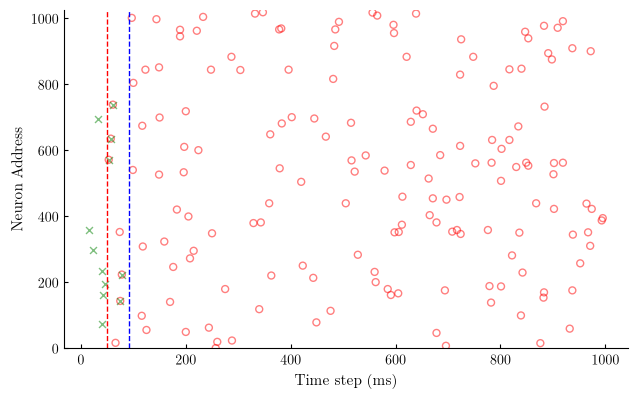

In [4]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'fraction_target', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: F1-score for different numbers of silenced trigger neurons

`get_scores_fraction`: `N_scan=36` values linspace(0, N_neuron) of silenced rows;
one trigger + forward pass + evoked-window `get_f1score` each. The curve locates the
*robustness threshold* - how large a lesion before the memory fails to ignite.
Cached as `<datetag>_N_neurons.npz` under the `.lock` protocol.

In [5]:
# One cue realisation per repetition (seeded nb 20-style); the spatial lesion is re-
# applied to each fresh cue and scored against the clean frozen_target; the cache is
# saved after every lesion size (with an n_done sentinel) so an interrupted run can
# resume from the file and a partial file is never mistaken for a complete one.

def get_scores_fraction(N_scan=opt.N_scan, N_cv=opt.N_cv):
    N_neurons = np.linspace(0, hd.opt.N_neuron, N_scan, endpoint=True, dtype=int)
    scores_motif_np = np.zeros((N_scan, N_cv, hd.opt.N_pattern)) # F1 of each motif
    scores_np = np.zeros((N_scan, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_N_neuron in trange(N_scan):
        N_neuron = N_neurons[i_N_neuron]
        for i_cv in range(N_cv):
            with torch.no_grad():
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_, seed=seed)
                input_spikes[:, :(N_neuron), (hd.opt.N_pretime):(hd.opt.N_pretime+hd.opt.num_delay)] *= 0
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_N_neuron, i_cv] = get_f1score(spikes_evoked, target_evoked)
                scores_motif_np[i_N_neuron, i_cv] = get_f1score(spikes_evoked, target_evoked, dim=(1, 2)).cpu().numpy()
                seed += 1

        np.savez(npy_filename, N_neurons=N_neurons, scores_np=scores_np, scores_motif_np=scores_motif_np, n_done=i_N_neuron + 1) # incremental save

    return N_neurons, scores_np, scores_motif_np

npy_filename = data_cache / f"{hd.opt.datetag}_N_neurons.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    N_neurons = data['N_neurons']
    scores_np = data['scores_np']
    if data['scores_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (data['n_done'] != opt.N_scan) or ('scores_motif_np' not in data):
        raise ValueError(f"Partial score file: {npy_filename}, re-evaluating.")
    scores_motif_np = data['scores_motif_np']
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    with cache_lock(npy_filename) as acquired:
        if acquired:
            print(f"Score file not found: {npy_filename}, evaluating the score.")
             ##################
            N_neurons, scores_np, scores_motif_np = get_scores_fraction()
             ##################
            np.savez(npy_filename, N_neurons=N_neurons, scores_np=scores_np, scores_motif_np=scores_motif_np, n_done=opt.N_scan)
        else:
            print(f"Score file is locked: {lock_filename}, passing.")

Score weights loaded from ../cached_data/2026-09-07_N_neurons.npz


In [6]:
# sanity check that scan vectors are aligned.

N_neurons.shape, scores_np.shape

((14,), (14, 11))

## Expected F1 from theory

The ignition model of notebook 14 (`get_f1_ignition`) applies to a trigger in which $n$ of the
$N$ neurons are silenced. With the minimum-norm (pseudo-inverse) readout, a spike of a motif is
supported, with equal weights, by the $K$ spikes of that motif in the $D$ bins before it, and is
emitted if at least $\lceil \vartheta K \rceil$ of them are present, $\vartheta$ being the firing
threshold. The replay is a cascade, a positive feedback loop: each emitted spike joins the support of the
next ones. Once the first evoked spike of a motif is emitted, the following ones find more and more
of their support, and the replay ignites as a whole and sustains itself; if it fails, their support
keeps shrinking and the replay dies out (see the dynamics below). The ignition probability $R$ is
thus that of the first evoked spike. A motif fires $\mu = p_A N$ spikes per bin, so this spike
comes $j$ bins after the trigger with probability $P(j) = e^{-\mu j}(1 - e^{-\mu})$, and its $K$
supporting spikes, in the last $D - j$ bins of the trigger window, follow a Poisson law of mean
$\lambda_j = \mu (D - j)$. As with flips, the missing spikes are scattered across the
window, so that a supporting spike is present with the same probability whatever $j$:

$$q_j = q = \Big(1 - \frac{n}{N}\Big)\big(1 - p_\mathrm{flip}\,(1 - p_A)\big),$$

where $p_\mathrm{flip}$ is the bit-flip probability of the cue and $p_A$ the firing probability
of the motif. The ignition probability is

$$R = \frac{1}{R_0} \sum_{j=0}^{D-1} P(j) \sum_{K \geq 1} \frac{e^{-\lambda_j} \lambda_j^K}{K!} \sum_{k = \lceil \vartheta K \rceil}^{K} \binom{K}{k}\, q_j^k (1 - q_j)^{K - k},$$

normalised by its value $R_0 \approx 0.991$ for the intact trigger ($q_j = 1$: the first evoked
spike fires if it has at least one supporting spike), whose rare failures are already counted in
the measured recall.

As in notebook 14, $F_1 = 2\, R\, r_0 / (1 + R\, r_0 / \pi_0)$, with $\pi_0$ and $r_0$ the precision
and recall with the intact trigger ($n = 0$).

**Two theories.** The formula above is the *first-spike theory* (orange line): it computes, in
closed form, only the first step of the cascade, averaged over the Poisson statistics of the
support. The *cascade theory* (green line, `get_f1_cascade`) simulates the whole replay instead:
1000 random motifs with the same statistics and the whole duration $T$, bin after bin, the emitted
spikes joining the support of the next ones, with the identity of the neurons kept in the trigger
window. The two theories agree when the first evoked spike decides the replay. Neither has a
fitted parameter: the threshold is the LIF threshold of the network, and only $\pi_0$ and $r_0$
are measured. Both theories average over random motifs, whereas the lesion
always silences the same addresses (0 to $n - 1$) of the $M = 16$ motifs of the network: the few
motifs whose trigger spikes mostly fall on high addresses keep igniting, which can leave a plateau
above the curves.

| symbol | name in the code | default value | role |
|---|---|---|---|
| $n$ | `N_neurons` | swept from 0 to 1024 in 14 steps | number of silenced trigger neurons |
| $N$ | `N_neuron` | 1024 | number of neurons |
| $D$ | `num_delay` | 41 bins (41 ms) | width of the spiking-motif window |
| $p_\mathrm{flip}$ | `p_flip` | 0.01 | bit-flip probability of the cue |
| $p_A$ | `p_A` | $1.6 \times 10^{-4}$ per 1 ms bin (0.16 Hz) | firing probability of the motif |
| $\vartheta$ | `lif_threshold` | 0.75 | firing threshold, relative to the membrane potential reached on the motif |
| $\mu$ | `p_A * N_neuron` | 0.164 spike per bin | mean number of spikes of a motif per bin |
| $j$ | - | 0 to $D - 1$ bins (mean 5.6 ms) | delay of the first evoked spike after the trigger |
| $\lambda_j$ | `mu * (num_delay - j)` | 6.72 for $j = 0$ | mean number of spikes supporting the first evoked spike |
| $q$ | `get_trigger_presence` | - | probability that a supporting spike is present in the trigger |
| $R$, $R_0$ | - | $R_0 \approx 0.991$ | ignition probability of a motif, and its value with an intact trigger |
| $\pi_0$, $r_0$ | `precision_0`, `recall_0` | measured with $n = 0$ | precision and recall with the intact trigger |

The cell below measures $\pi_0$ and $r_0$ with the first repetition of the sweep protocol (same
seed, no lesion), evaluates both theories, and reports their RMS error on the sweep. In the score
figure, the orange line is the first-spike theory, the green line the cascade theory, and the grey
dashed lines mark $F_1 = 0$ and $F_1 = 1$.

In [7]:
# Precision and recall of the replay with the intact trigger (first repetition of the sweep
# protocol, same seed): the only measured inputs of the ignition model.

with torch.no_grad():
    target_ = hd.pattern_object(seed=opt.seed)
    _, _, spikes = hd.forward_pass(hd.get_input_spikes(target=target_, seed=opt.seed))
    spikes_evoked = spikes[:, :, (opt.N_pretime+opt.num_delay):(opt.N_time+opt.N_pretime)]
    target_evoked = hd.pattern_object.frozen_target[:, :, opt.num_delay:]
    precision_0, recall_0, f1_score_0 = [score.item() for score in get_scores(spikes_evoked, target_evoked)]
print(f'intact trigger: precision = {precision_0:.3f}\t recall = {recall_0:.3f}\t f1_score = {f1_score_0:.3f}')

theory_dict = dict(p_flip=opt.p_flip, p_A=opt.p_A, N_neuron=opt.N_neuron, num_delay=opt.num_delay,
                   lif_threshold=opt.lif_threshold, precision_0=precision_0, recall_0=recall_0)
# lesioned trigger: a fraction 1 - n / N of the neurons is shown, the losses are scattered
N_neurons_theory = np.linspace(0, opt.N_neuron, 201)
f1_ignition_theory = get_f1_ignition(fraction=1 - N_neurons_theory/opt.N_neuron, **theory_dict)
f1_cascade_theory = get_f1_cascade(fraction=1 - N_neurons_theory/opt.N_neuron, N_time=opt.N_time, **theory_dict) # whole replay, simulated
if not lock_filename.exists():
    for name, f1_scan in [('first-spike', get_f1_ignition(fraction=1 - N_neurons/opt.N_neuron, **theory_dict)),
                          ('cascade', get_f1_cascade(fraction=1 - N_neurons/opt.N_neuron, N_time=opt.N_time, **theory_dict))]:
        print(f'RMS error of the {name} theory on the sweep = {np.sqrt(np.mean((f1_scan - scores_np.mean(axis=1))**2)):.3f}')

intact trigger: precision = 0.835	 recall = 0.825	 f1_score = 0.830


RMS error of the first-spike theory on the sweep = 0.061
RMS error of the cascade theory on the sweep = 0.061


Saving as ../figures/fraction_target_score.pdf
Saving as ../figures/fraction_target_score.png
Saving as ../figures/fraction_target_score.svg


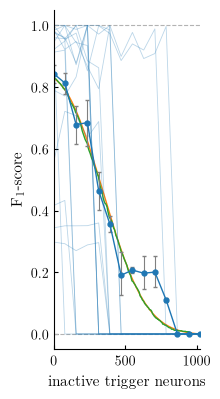

In [8]:
# $F_1$ vs number of inactive trigger neurons, mean and 5%-95% quantiles of a beta fit over N_cv realisations;
# thin lines for each motif; grey guides at 0 and 1; orange: first-spike theory; green: cascade theory.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], N_neurons[0], N_neurons[-1], '0.7', ls='--', lw=0.8)
    ax.plot(N_neurons_theory, f1_ignition_theory, color='tab:orange')
    ax.plot(N_neurons_theory, f1_cascade_theory, color='tab:green')
    # one thin line per motif (F1 of the motif, mean over the N_cv realisations), overlaid on the
    # mean: each motif switches from 0 to its intact value at its own threshold (all-or-nothing ignition)
    ax.plot(N_neurons, scores_motif_np.mean(axis=1), color='tab:blue', alpha=.3, lw=.6)
    mean, yerr = get_beta_errorbar(scores_np)
    ax.errorbar(N_neurons, mean, yerr=yerr, fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0)
    ax.set_xlabel(r"inactive trigger neurons")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(N_neurons[0], N_neurons[-1])
    ax.set_ylim(-0.05, 1.05)

    printfig(fig, 'fraction_target_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)


## Dynamics of the replay: a cascade

The ignition model assumes that the replay of each motif either ignites as a whole and sustains
itself, or dies out. The recall of each motif in successive windows of $D = 41$ ms of the evoked
window (`HD_SNN.get_recall_time`) shows it directly, for a few lesion sizes (thin lines: single
motifs; thick lines: mean over the $M = 16$ motifs): each motif settles on the recall of the
intact trigger or on zero, a bistable dynamics, and the lesion only changes the number of
motifs that ignite. In the open-loop control (dashed black, `forward_pass(..., feedback=False)`,
with the intact trigger), the output spikes are not fed back: each neuron only sees the trigger,
which drives the first $D$ ms of the evoked window, after which the activity vanishes. The replay
is thus sustained by the recurrent positive feedback, not by the trigger. A few motifs stop late
in the evoked window even with the intact trigger: these failures do not depend on the trigger and
are part of the measured recall $r_0$.

Saving as ../figures/fraction_target_cascade.pdf
Saving as ../figures/fraction_target_cascade.png
Saving as ../figures/fraction_target_cascade.svg


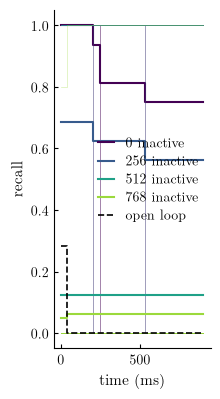

In [9]:
# Recall of each motif per window of num_delay bins for a few lesion sizes (closed loop), and
# for the open-loop control (output spikes not fed back) with the intact trigger.

N_neurons_levels = [0, 256, 512, 768]
cue = hd.pattern_object(seed=opt.seed)
recall_time = []
for N_neurons_level in N_neurons_levels:
    input_spikes = hd.get_input_spikes(target=cue, seed=opt.seed)
    input_spikes[:, :N_neurons_level, opt.N_pretime:(opt.N_pretime+opt.num_delay)] *= 0
    recall_time.append(hd.get_recall_time(input_spikes))
recall_open = hd.get_recall_time(hd.get_input_spikes(target=cue, seed=opt.seed), feedback=False)
labels = [f'{N_neurons_level} inactive' for N_neurons_level in N_neurons_levels]

fig, ax = plt.subplots()
plot_recall_time(ax, recall_time, labels, recall_open=recall_open, bin_width=opt.num_delay)
ax.legend(loc='center right', handlelength=1.2, labelspacing=0.3)
printfig(fig, 'fraction_target_cascade', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)